# Estimated new cases of lip and oral cavity cancer by country, 2022

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shah-pushti/oral-cancer-figures/blob/main/notebooks/cases-by-country.ipynb)

This notebook rebuilds the country chart of the article [Oral cancer: estimated new cases by country and five-year survival by stage at diagnosis](https://shah-pushti.github.io/oral-cancer-in-numbers.html). It plots the GLOBOCAN 2022 estimates for the countries with the most new cases, and next to them the age-standardised incidence rate, which corrects for population size and age.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Read the data from this repository; in Colab, read it from GitHub.
BASE = Path("..") if Path("../data").exists() else None
RAW = "https://raw.githubusercontent.com/shah-pushti/oral-cancer-figures/main/"

def load(name):
    return pd.read_csv(BASE / "data" / name if BASE else RAW + "data/" + name)

INK, BURGUNDY, STEEL, PAPER = "#231920", "#6E1A2D", "#3F6068", "#F7F8F5"
plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "text.color": INK, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})
OUT = Path("../figures") if BASE else Path("figures")
OUT.mkdir(exist_ok=True)

In [2]:
df = load("globocan2022-lip-oral-cavity-countries.csv")
df

,country,new_cases_2022,asr_incidence_per_100000,source
0,India,143759,9.9,WCRF GLOBOCAN 2022
1,China,37208,1.5,WCRF GLOBOCAN 2022
2,United States,27750,4.6,WCRF GLOBOCAN 2022
3,Bangladesh,16083,10.3,WCRF GLOBOCAN 2022
4,Pakistan,15915,9.2,WCRF GLOBOCAN 2022


Case counts follow population size. The age-standardised rate (ASR) shows how common the cancer is relative to the population, so the two panels rank the countries differently.

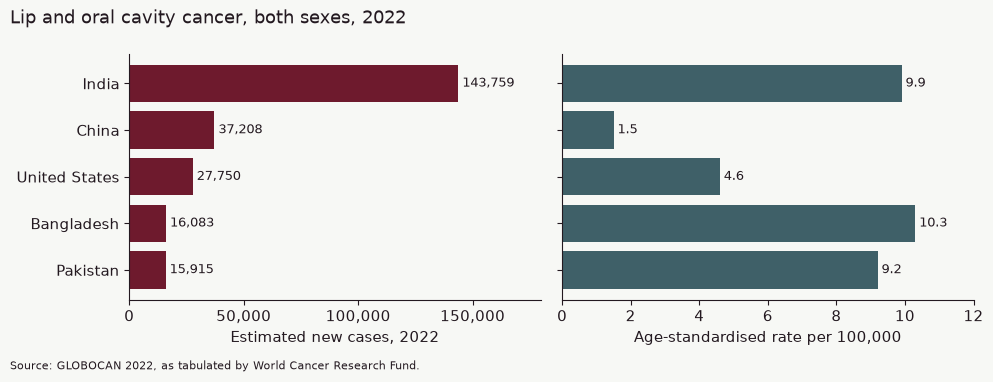

In [3]:
df = df.sort_values("new_cases_2022")
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
a.barh(df["country"], df["new_cases_2022"], color=BURGUNDY)
a.set_xlabel("Estimated new cases, 2022")
for y, v in enumerate(df["new_cases_2022"]):
    a.text(v, y, f" {v:,}", va="center", fontsize=9)
a.set_xlim(0, df["new_cases_2022"].max() * 1.25)
a.set_xticks([0, 50000, 100000, 150000])
a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
b.barh(df["country"], df["asr_incidence_per_100000"], color=STEEL)
b.set_xlabel("Age-standardised rate per 100,000")
for y, v in enumerate(df["asr_incidence_per_100000"]):
    b.text(v, y, f" {v}", va="center", fontsize=9)
b.set_xlim(0, 12)
fig.suptitle("Lip and oral cavity cancer, both sexes, 2022", x=0.01, ha="left")
fig.text(0.01, -0.02, "Source: GLOBOCAN 2022, as tabulated by World Cancer Research Fund.", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "cases-by-country.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT / "cases-by-country.svg", bbox_inches="tight")

In [4]:
share_india = 143759 / 389846
print(f"India's share of estimated new cases worldwide: {share_india:.1%}")

India's share of estimated new cases worldwide: 36.9%


## Sources

- World Cancer Research Fund. Mouth and oral cancer statistics (GLOBOCAN 2022). https://www.wcrf.org/preventing-cancer/cancer-statistics/mouth-and-oral-cancer-statistics/
- Worldwide total (389,846 new cases) as reported in the same source.